# Crunchbase Investments Analysis

## Dataset introduction

This notebook analyzes a **company-level Crunchbase investment dataset**. Each row represents a company and summarizes information about its **market/sector, location, operating status, funding history, funding dates, and amounts raised through different funding types and rounds**.

The project focuses on three main goals:

1. **Clean the dataset efficiently using chunks**, so the entire CSV does not need to be loaded into memory at once.
2. **Reduce memory usage** by removing redundant or low-value columns and fixing data types.
3. **Store and analyze the cleaned data with SQLite**, using SQL for aggregation and Pandas/Matplotlib for visualization.



In [10]:
import pandas as pd 

chunk_iter = pd.read_csv('investments_VC.csv',chunksize=5000, encoding='ISO-8859-1')
cb_length = []

for chunk in chunk_iter:
    cb_length.append(len(chunk))

cb_length = sum(cb_length)

print("Number of rows:", cb_length)

Number of rows: 54294


### Missing-value analysis using chunks

The CSV is processed in chunks of 5,000 rows to count missing values without loading the full dataset into memory.

In [11]:
chunk_iter = pd.read_csv('investments_VC.csv',chunksize=5000, encoding='ISO-8859-1')

mv_list = []
for chunk in chunk_iter:
    mv_list.append(chunk.isnull().sum())
    
combined_mv_vc = pd.concat(mv_list) # concating chunks mv
unique_combined_mv_vc = combined_mv_vc.groupby(combined_mv_vc.index).sum() 
unique_combined_mv_vc.sort_values()

 funding_total_usd       4856
angel                    4856
debt_financing           4856
convertible_note         4856
grant                    4856
funding_rounds           4856
first_funding_at         4856
equity_crowdfunding      4856
round_A                  4856
round_B                  4856
product_crowdfunding     4856
private_equity           4856
post_ipo_debt            4856
post_ipo_equity          4856
permalink                4856
last_funding_at          4856
round_F                  4856
round_E                  4856
round_C                  4856
round_D                  4856
round_G                  4856
seed                     4856
secondary_market         4856
round_H                  4856
undisclosed              4856
venture                  4856
name                     4857
status                   6170
homepage_url             8305
category_list            8817
 market                  8824
country_code            10129
region                  10129
city      

The columns `founded_quarter`, `founded_year`, and `founded_month` contain many missing values. Since `founded_at` already provides the complete founding date, these columns are redundant and can be removed.

We can also remove `state_code`. It contains many missing values and is mainly useful for U.S specific analysis, while broader location fields such as `country_code`, `region`, and `city` are more suitable for an international dataset.

### Memory usage by column

The following step measures how much memory each column occupies across all chunks. This helps identify memory-heavy columns that may not be necessary for the analysis.

In [12]:
chunk_iter = pd.read_csv('investments_VC.csv', chunksize=5000, encoding='ISO-8859-1')
counter = 0
series_memory_fp = pd.Series(dtype='float64')
for chunk in chunk_iter:
    if counter == 0:
        series_memory_fp = chunk.memory_usage(deep=True)
    else:
        series_memory_fp += chunk.memory_usage(deep=True)
    counter += 1
series_memory_fp = series_memory_fp.drop('Index').sort_values()
print(series_memory_fp,"\n")
print("Total Memory Used (mb)", series_memory_fp.sum() / (1024*1024))

founded_year             434352
funding_rounds           434352
round_A                  434352
product_crowdfunding     434352
post_ipo_equity          434352
private_equity           434352
secondary_market         434352
post_ipo_debt            434352
angel                    434352
grant                    434352
debt_financing           434352
convertible_note         434352
equity_crowdfunding      434352
undisclosed              434352
seed                     434352
venture                  434352
round_E                  434352
round_H                  434352
round_G                  434352
round_F                  434352
round_C                  434352
round_D                  434352
round_B                  434352
state_code               500924
country_code             573097
founded_quarter          709976
founded_month            709976
city                     818545
founded_at               826142
region                   850809
status                   862217
 funding

`homepage_url`, `category_list`, and `permalink` are among the most memory-intensive text columns. 

### Memory optimization

In [14]:
# Remove columns that are redundant or not needed for the analysis

drop_cols = [
    'homepage_url', 'permalink', 'founded_year', 'state_code',
    'founded_month', 'founded_quarter', 'category_list'
]

# Read only the header to determine which columns to keep
all_cols = pd.read_csv(
    'investments_VC.csv',
    nrows=0,
    encoding='ISO-8859-1'
).columns

keep_cols = all_cols.drop(drop_cols).tolist()

In [15]:
chunk_iter = pd.read_csv('investments_VC.csv', chunksize=5000, encoding='ISO-8859-1', usecols=keep_cols)
counter = 0
series_memory_fp_after = pd.Series(dtype='float64')

for chunk in chunk_iter:
    if counter == 0:
        series_memory_fp_after = chunk.memory_usage(deep=True)
    else:
        series_memory_fp_after += chunk.memory_usage(deep=True)
    counter += 1
series_memory_fp_after = series_memory_fp_after.drop('Index').sort_values()

print("Total Memory Used (mb)", series_memory_fp_after.sum() / (1024*1024))

Total Memory Used (mb) 17.494159698486328


**Optimization result:** In this run, memory usage decreased from approximately **24.45 MB to 17.49 MB**, saving about **7 MB**. Therefore, unnecessary columns are removed before the data is stored and analyzed.

In [18]:
import sqlite3

# Create / connect to the SQLite database
conn = sqlite3.connect("investments.db")

chunk_iter = pd.read_csv(
    'investments_VC.csv',
    chunksize=5000,
    encoding='ISO-8859-1',
    usecols=keep_cols
)

for chunk in chunk_iter:
    # Clean column names
    chunk.columns = chunk.columns.str.strip()

    # Remove rows where every value is missing
    chunk = chunk.dropna(how="all")

    # Remove duplicate rows inside the current chunk
    chunk = chunk.drop_duplicates()

    # Remove unnecessary whitespace from text columns
    text_cols = chunk.select_dtypes(include=["object", "string"]).columns
    for col in text_cols:
        chunk[col] = chunk[col].str.strip()

    # Convert funding_total_usd from text to a numeric column
    funding = (
        chunk["funding_total_usd"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.strip()
        .replace({"-": pd.NA, "": pd.NA})
    )
    chunk["funding_total_usd"] = pd.to_numeric(funding, errors="coerce")

    # Append the cleaned chunk to SQLite
    chunk.to_sql(
        "investments_raw",
        conn,
        if_exists="append",
        index=False
    )

# Remove duplicates across chunk boundaries using SQL
conn.execute("""
CREATE TABLE investments_clean AS
SELECT DISTINCT *
FROM investments_raw
""")

conn.commit()

## Exploratory analysis

The cleaned dataset is now stored in SQLite. Therefore only the smaller query results are loaded into Pandas for visualization.

### 1. Number of companies by country

In [19]:
query = """
SELECT country_code,
       COUNT(*) AS companies
FROM investments_clean
WHERE country_code IS NOT NULL
GROUP BY country_code
ORDER BY companies DESC
LIMIT 10;
"""

country_counts = pd.read_sql(query, conn)
country_counts

,country_code,companies
0,USA,28793
1,GBR,2642
2,CAN,1405
3,CHN,1239
4,DEU,968
5,FRA,866
6,IND,849
7,ISR,682
8,ESP,549
9,RUS,368


**Finding:** The United States is by far the most represented country in the dataset, with **28,793 companies**, followed by the United Kingdom (**2,642**) and Canada (**1,405**). This shows a strong geographic concentration in the U.S., so country-level comparisons should account for the uneven number of observations.

### 2. Total funding by market

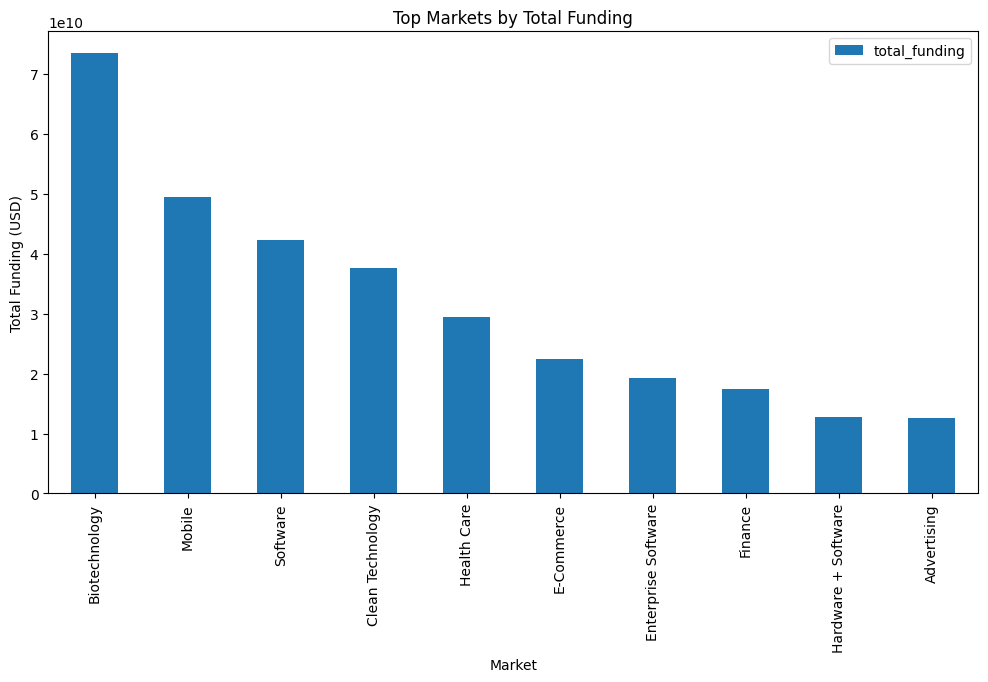

In [8]:
import matplotlib.pyplot as plt 


query = """
SELECT market,
       SUM(funding_total_usd) AS total_funding
FROM investments_clean
WHERE market IS NOT NULL
  AND funding_total_usd IS NOT NULL
GROUP BY market
ORDER BY total_funding DESC
LIMIT 10;
"""

market_funding = pd.read_sql(query, conn)

market_funding.plot(
    x="market",
    y="total_funding",
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top Markets by Total Funding")
plt.xlabel("Market")
plt.ylabel("Total Funding (USD)")
plt.show()

### 3. Company status

In [17]:
query = """
SELECT status,
       COUNT(*) AS companies
FROM investments_clean
WHERE status IS NOT NULL
GROUP BY status
ORDER BY companies DESC;
"""

status_df = pd.read_sql(query, conn)

status_df.plot(
    x="status",
    y="companies",
    kind="bar",
    figsize=(8, 5)
)

plt.title("Companies by Status")
plt.ylabel("Number of Companies")
plt.show()

NameError: name 'conn' is not defined

Most companies in the dataset are classified as **operating**, while much smaller groups are **acquired** or **closed** . This indicates that the dataset is dominated by companies that were still operating at the time the data was recorded.

### 4. First funding activity over time

In [16]:
query = """
SELECT
    strftime('%Y', first_funding_at) AS year,
    COUNT(*) AS companies
FROM investments_clean
WHERE first_funding_at IS NOT NULL
  AND CAST(strftime('%Y', first_funding_at) AS INTEGER) >= 1900
GROUP BY year
ORDER BY year;
"""

funding_year = pd.read_sql(query, conn)

funding_year.plot(
    x="year",
    y="companies",
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Companies Receiving First Funding by Year")
plt.xlabel("Year")
plt.ylabel("Number of Companies")
plt.show()

NameError: name 'conn' is not defined

**Finding:** The number of companies receiving their first recorded funding increases sharply after 2004 and continues rising through the late 2000s and early 2010s. The dataset reaches its highest count in 2013, followed by a small decline in 2014. The final-year decline should be interpreted cautiously because it may partly reflect dataset coverage rather than a real market contraction.

## Summary of findings

- The cleaning pipeline removes completely empty rows, redundant columns, unnecessary whitespace, and duplicates while processing the CSV in chunks.
- Removing low-value and redundant columns reduces memory usage substantially before analysis.
- The dataset is geographically concentrated in the **United States**, which has far more represented companies than any other country.
- **Biotechnology** has the highest total funding among the markets shown, followed by **Mobile** and **Software**.
- Most companies are classified as **operating**, with much smaller numbers marked as acquired or closed.
- First-funding activity rises sharply after the mid-2000s and reaches its highest recorded count in **2013** within this dataset.

These findings describe the records contained in this dataset and should not automatically be interpreted as complete measures of the global venture-capital market.